In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as io   # io.imread(...) = plt.imread(...), évite d'installer scikit-image

Le script qui suit permet de charger une image qui servira de modèle puis de la visualiser :

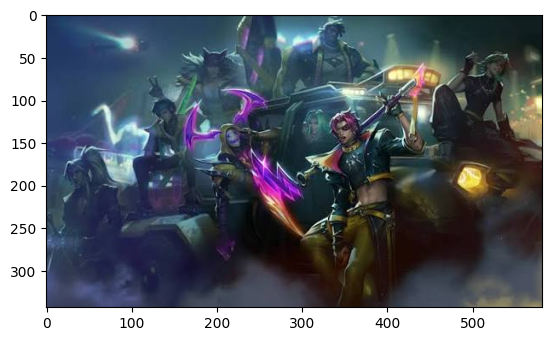

In [2]:
image = plt.imread("test1.jpg")
plt.imshow(image)
plt.show()

In [3]:
image.shape

(343, 582, 3)

## 2. Fonctions élémentaires

**Question 1.** Rédiger une fonction `symetrie` qui prend en argument une image et retourne une nouvelle image, obtenue par symétrie autour d'un axe vertical passant par le milieu de l'image.

*Indication :* la fonction `np.zeros_like(m)` crée un tableau nul de même type et de mêmes dimensions que le tableau `m`.

In [4]:
def symetrie(im):
    n, p, c = im.shape
    im_sym = np.zeros_like(im)
    for i in range(n):
        for j in range(p):
            im_sym[i, j] = im[i, p - 1 - j]
    return im_sym

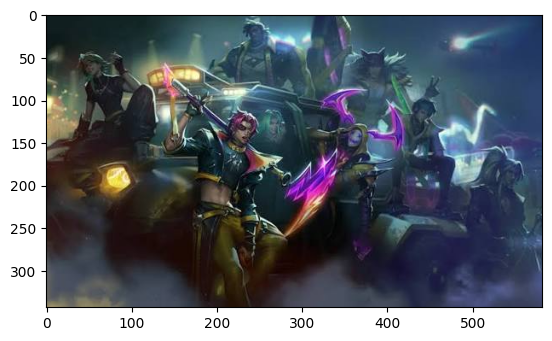

In [5]:
plt.imshow(symetrie(image))
plt.show()

**Question 2.** Rédiger une fonction `negatif` qui prend en argument une image et retourne son négatif, c'est-à-dire l'image dans laquelle chaque composante de couleur de chaque pixel est remplacée par sa valeur complémentaire dans l'intervalle [0, 255].

In [6]:
def negatif(im):
    n, p, c = im.shape
    im_neg = np.zeros_like(im)
    for i in range(n):
        for j in range(p):
            im_neg[i, j] = 255 - im[i, j]
    return im_neg

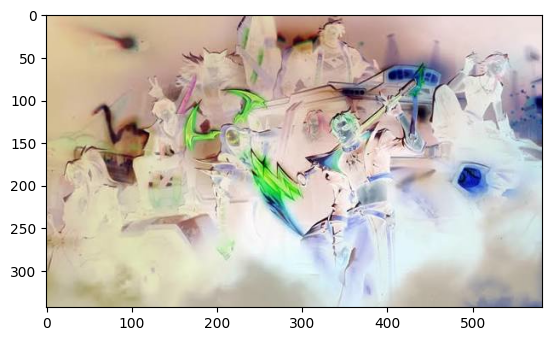

In [7]:
plt.imshow(negatif(image))
plt.show()

**Conversion en niveau de gris :** pour convertir une image couleur en niveau de gris, un pixel représenté par ses composantes (r, g, b) doit être remplacé par un pixel à une seule composante y ∈ [0, 255] appelée luminance. Cette quantité, qui traduit la sensation visuelle de luminosité, dépend de manière inégale des trois composantes RGB. La formule communément recommandée pour cette conversion est la suivante :

y = 0,2126 r + 0,7152 g + 0,0722 b  (y étant arrondi à l'entier le plus proche)

(pour un œil humain le vert paraît plus lumineux que le rouge, lui-même plus lumineux que le bleu).

**Question 4.** Rédiger une fonction `niveaudegris` qui prend en argument une image couleur et retourne une nouvelle image convertie en niveau de gris.

*(L'énoncé saute la question 3.)*

In [8]:
def niveaudegris(im):
    n, p, c = im.shape
    im_lum = np.zeros((n, p), dtype=np.uint8)
    for i in range(n):
        for j in range(p):
            r, g, b = float(im[i, j, 0]), float(im[i, j, 1]), float(im[i, j, 2])
            im_lum[i, j] = np.round(0.2126 * r + 0.7152 * g + 0.0722 * b)
    return im_lum

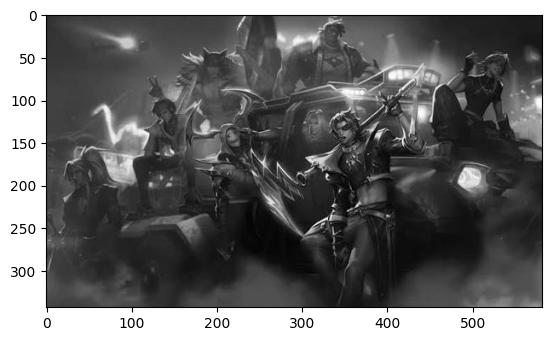

In [9]:
plt.imshow(niveaudegris(image), cmap='gray')
plt.show()

**Question 5.** Écrire une fonction qui renvoie le canal rouge de l'image.

In [10]:
def image_rouge(im):
    photo_rouge = np.zeros(im.shape, dtype=np.uint8)   # créer une matrice de même dimension
    photo_rouge[:, :, 0] = im[:, :, 0]
    return photo_rouge

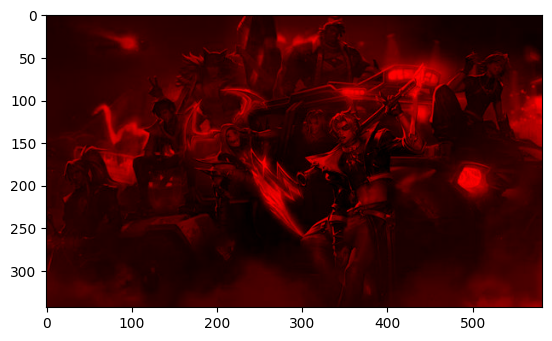

In [11]:
plt.imshow(image_rouge(image))
plt.show()

**Question 6.** Écrire une fonction qui renvoie le canal vert de l'image.

In [12]:
def image_verte(im):
    photo_verte = np.zeros(im.shape, dtype=np.uint8)
    photo_verte[:, :, 1] = im[:, :, 1]
    return photo_verte

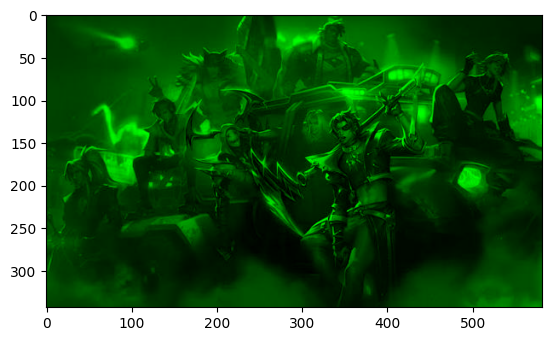

In [13]:
plt.imshow(image_verte(image))
plt.show()

**Question 7.** Écrire une fonction qui renvoie le canal bleu de l'image.

In [14]:
def image_bleue(im):
    photo_bleue = np.zeros(im.shape, dtype=np.uint8)
    photo_bleue[:, :, 2] = im[:, :, 2]
    return photo_bleue

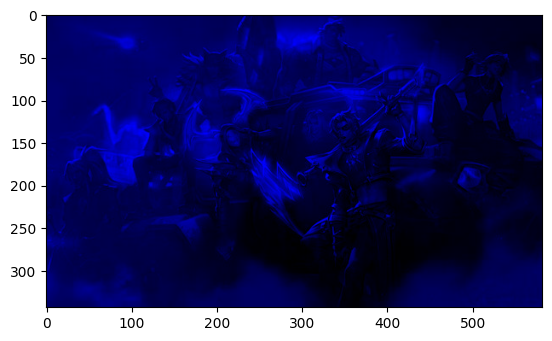

In [15]:
plt.imshow(image_bleue(image))
plt.show()

In [16]:
def histo(im):
    H = np.zeros(256)
    for i in range(len(im)):
        for j in range(len(im[0])):
            H[im[i][j]] += 1
    return H

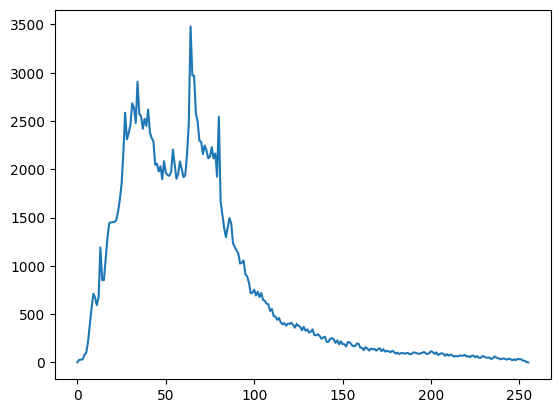

In [17]:
plt.plot(np.arange(256), histo(niveaudegris(image)))   # X et Y sont les listes (ou tableaux numpy)
plt.show()                                             # pour afficher

Chargement de la deuxième image (niveaux de gris), puis son histogramme :

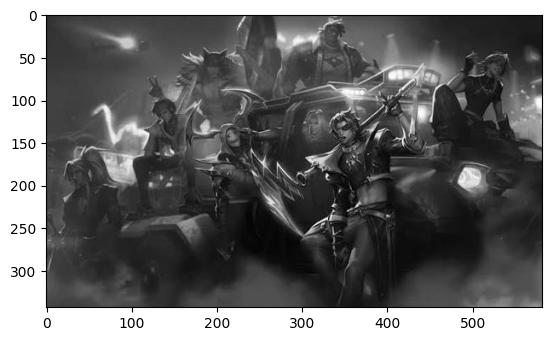

In [18]:
image2 = io.imread("test2.jpg")
image2 = niveaudegris(image2)
plt.imshow(image2, cmap='gray')
plt.show()

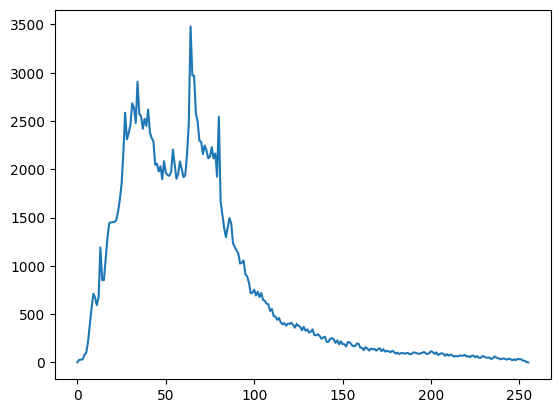

In [19]:
plt.plot(np.arange(256), histo(image2))   # X et Y sont les listes (ou tableaux numpy)
plt.show()                                # pour afficher

**Question 9.** Écrire une fonction `egaliser_histogramme(H, gray_image)`, qui prend en paramètre un histogramme `H` et une image en niveaux de gris `gray_image`, la fonction retourne l'histogramme égalisé.

In [20]:
def egaliser_histogramme(H, gray_image):
    # histogramme cumulé
    hc = np.zeros(len(H))
    hc[0] = H[0]
    for i in range(1, len(H)):
        hc[i] = hc[i - 1] + H[i]
    # normaliser l'histogramme cumulé
    he = (hc / gray_image.size) * 255
    return he

**Question 10.** Écrire une fonction `augmenter_contraste(gray_image)`, qui prend en paramètre une image en niveaux de gris `gray_image`, la fonction retourne une nouvelle image avec un contraste augmenté.

In [21]:
def augmenter_contraste(gray_image):
    H = histo(gray_image)
    he = egaliser_histogramme(H, gray_image)
    # Utilise he comme table de conversion des niveaux de gris
    new_image = gray_image.copy()
    for i in range(0, gray_image.shape[0]):        # énumère les lignes
        for j in range(0, gray_image.shape[1]):    # énumère les colonnes
            new_image[i, j] = int(he[gray_image[i, j]])
    return new_image

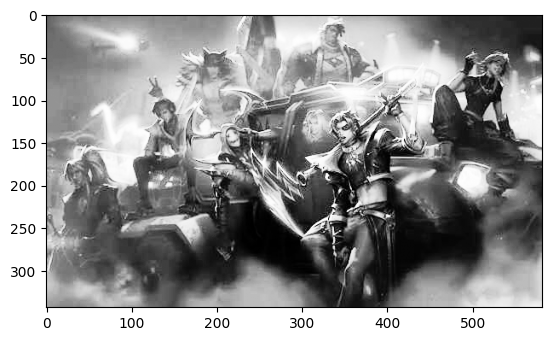

In [22]:
plt.imshow(augmenter_contraste(image2), cmap='gray')
plt.show()

**Comparaison avant / après égalisation** (images et histogrammes) :

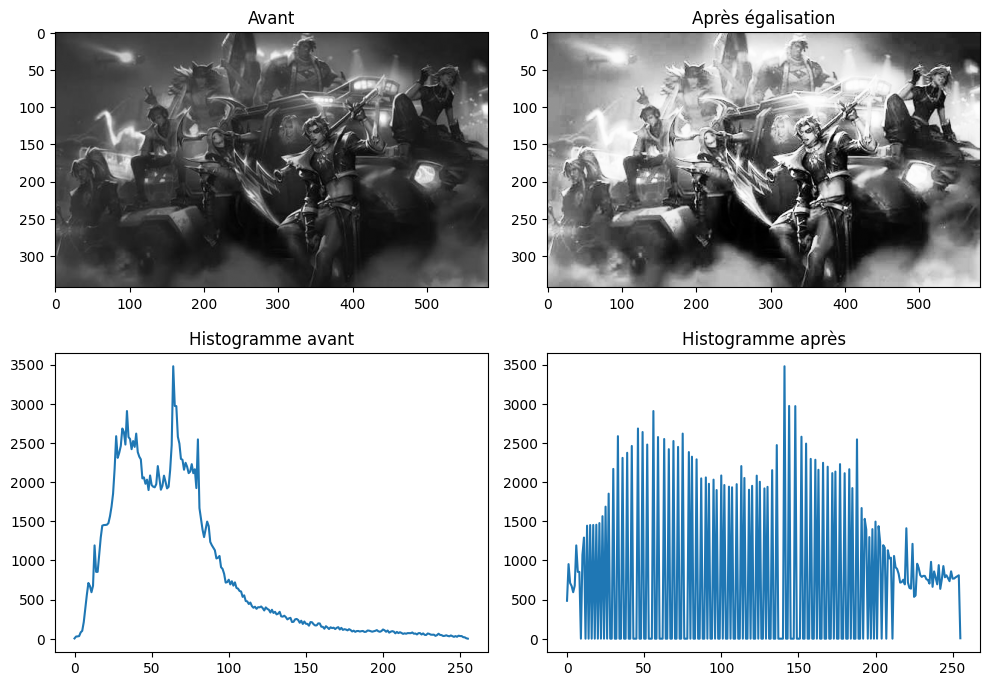

In [23]:
img_eq = augmenter_contraste(image2)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].imshow(image2, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Avant")
axes[0, 1].imshow(img_eq, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title("Après égalisation")
axes[1, 0].plot(histo(image2))
axes[1, 0].set_title("Histogramme avant")
axes[1, 1].plot(histo(img_eq))
axes[1, 1].set_title("Histogramme après")
plt.tight_layout()
plt.show()